# Dubins car: MPC under perception error (RoVer-CoRe method)

One circular obstacle; all experiment settings live in `config.py`.

Each stage loads its cached result from `.cache/<tag>/`, or rebuilds it if missing, built with a different config, or downstream of a rebuilt stage.
Figures are shown and saved to `outputs/<tag>/figures/`. Set `REBUILD = True` to force a rebuild. Build times on this machine: GridInput ~2 min (47 CPU workers), GridSet ~3 s, each BRT ~10 s (GPU).

In [1]:
%load_ext autoreload
%autoreload 2

import os

os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")
import matplotlib.pyplot as plt
import numpy as np

from toy_example import cache
from toy_example.config import Config
from toy_example.controllers.mpc import MPC
from toy_example.grids import grid_input, grid_set
from toy_example.reachability import brt_sweep, grid_value
from toy_example.simulation import uncertainty
from toy_example.simulation.initial_states import INITIAL_STATES
from toy_example.simulation.simulator import simulate
from toy_example.visualization.common import save_fig
from toy_example.visualization.rollout import plot_rollout, rollout_title
from toy_example.visualization.slices import plot_brt, plot_brt_sweep, plot_brt_tube, plot_failure, plot_grid_input, plot_grid_set

REBUILD = False
THETAS = (-np.pi / 6, 0.0, np.pi / 6)  # θ slices for all slice plots (snapped to the nearest grid node)
cfg = Config()
x0 = INITIAL_STATES


def stale(path):
    return REBUILD or not cache.is_current(path, cfg.to_dict())


sys = cfg.system
print(cfg.tag)

one_obstacle


## 1. System

speed          3.0 m/s
omega max      1.0 rad/s
goal           (20.0, 0.0)
obstacle       center (10.0, 0.0), radius 2.0 m
state box      x [0.0, 20.0], y [-5.0, 5.0], θ [-3.1416, 3.1416]
time horizon   5.0 s
error bound    E = ±(0.5, 0.5, 0.1)  (x, y, θ)
grid           (101, 101, 101)
MPC            dt 0.1 s, horizon 5 steps, obstacle margin 0.5 m
initial states (x, y, θ):
[[ 1.   1.   0. ]
 [ 2.  -4.   0. ]
 [ 2.  -2.   0. ]
 [ 2.   0.   0. ]
 [ 2.   2.   0. ]
 [ 4.  -1.   0. ]
 [ 5.   4.5  0. ]
 [ 6.  -1.5  0. ]
 [ 6.   0.5  0. ]
 [ 6.   2.5  0. ]]


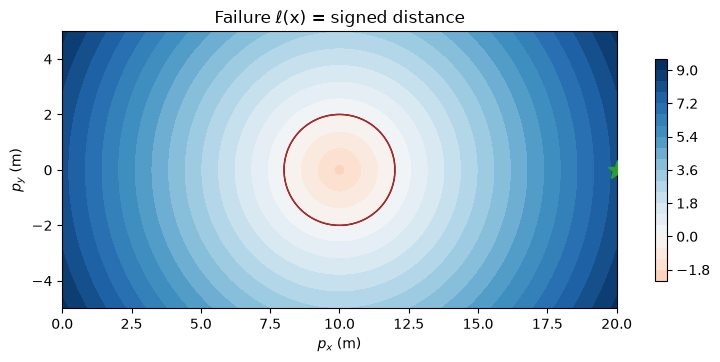

In [2]:
m = cfg.mpc
print(f"speed          {sys.speed} m/s")
print(f"omega max      {sys.omega_max} rad/s")
print(f"goal           {sys.goal}")
for o in sys.obstacles:
    print(f"obstacle       center ({o.cx}, {o.cy}), radius {o.radius} m")
print(f"state box      x [{sys.state_lo[0]}, {sys.state_hi[0]}], y [{sys.state_lo[1]}, {sys.state_hi[1]}], θ [{sys.state_lo[2]:.4f}, {sys.state_hi[2]:.4f}]")
print(f"time horizon   {sys.time_horizon} s")
print(f"error bound    E = ±{sys.error_bound}  (x, y, θ)")
print(f"grid           {cfg.grid.resolution}")
print(f"MPC            dt {m.dt} s, horizon {m.horizon} steps, obstacle margin {m.obstacle_margin} m")
print("initial states (x, y, θ):")
print(x0)


fig = plot_failure(sys)
save_fig(fig, cfg, "1_failure")
plt.show()

## 2. MPC
Closed-loop rollouts with the MPC itself (no grid), perfect state estimation.

effective obstacle margin: 1.207 m


7.8 ms per MPC solve


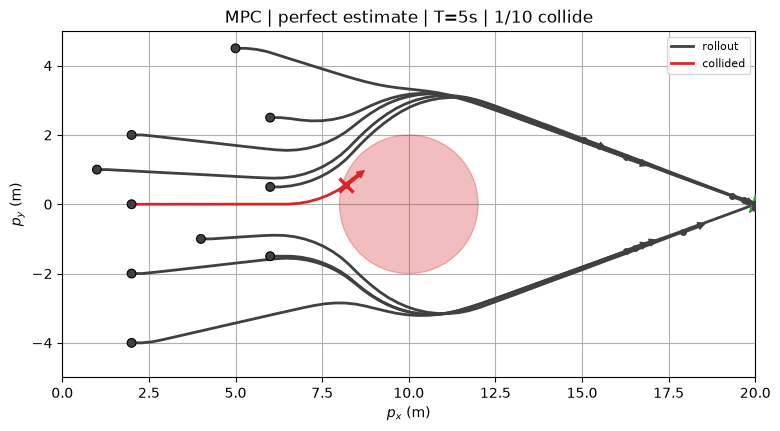

In [3]:
import time

mpc = MPC(cfg.mpc, sys)
print(f"effective obstacle margin: {mpc.margin:.3f} m")
t0 = time.perf_counter()
ro_mpc = simulate(sys, mpc, uncertainty.zero(), x0, dt=cfg.mpc.dt)
per_solve = (time.perf_counter() - t0) / ro_mpc.controls.size
mpc.close()
print(f"{per_solve * 1e3:.1f} ms per MPC solve")

fig = plot_rollout(sys, ro_mpc, rollout_title("MPC", "zero", sys, ro_mpc), show_estimate=False)
save_fig(fig, cfg, "2_mpc_rollout")
plt.show()

## 3. GridInput
MPC evaluated at every grid node; the deployed controller is a nearest-node lookup.

shape (101, 101, 101) | ω range -1.0000000099996975 1.0000000099282391


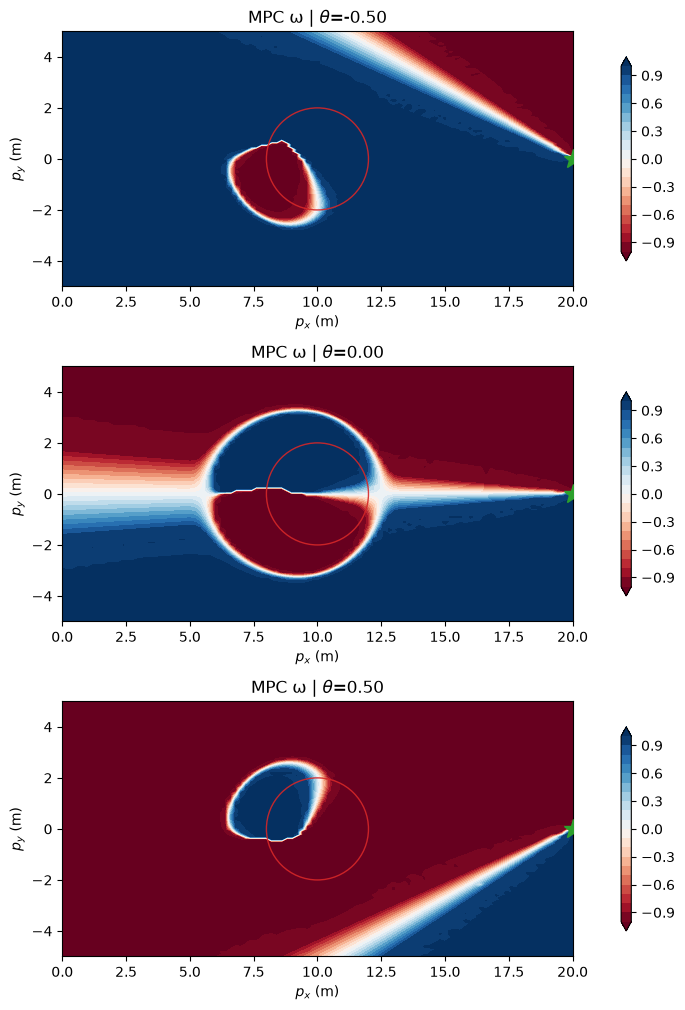

In [4]:
rebuilt_gi = stale(grid_input.path(cfg))
gi = grid_input.build(cfg) if rebuilt_gi else grid_input.load(cfg)
print("shape", gi.values.shape, "| ω range", gi.values.min(), gi.values.max())
fig = plot_grid_input(sys, gi, THETAS)
save_fig(fig, cfg, "3_grid_input")
plt.show()

## 4. GridSet
Bounds of GridInput over the nodes inside x + E (θ wraps across ±π).

width: mean 0.285, max 2.000, fraction > 0: 1.000


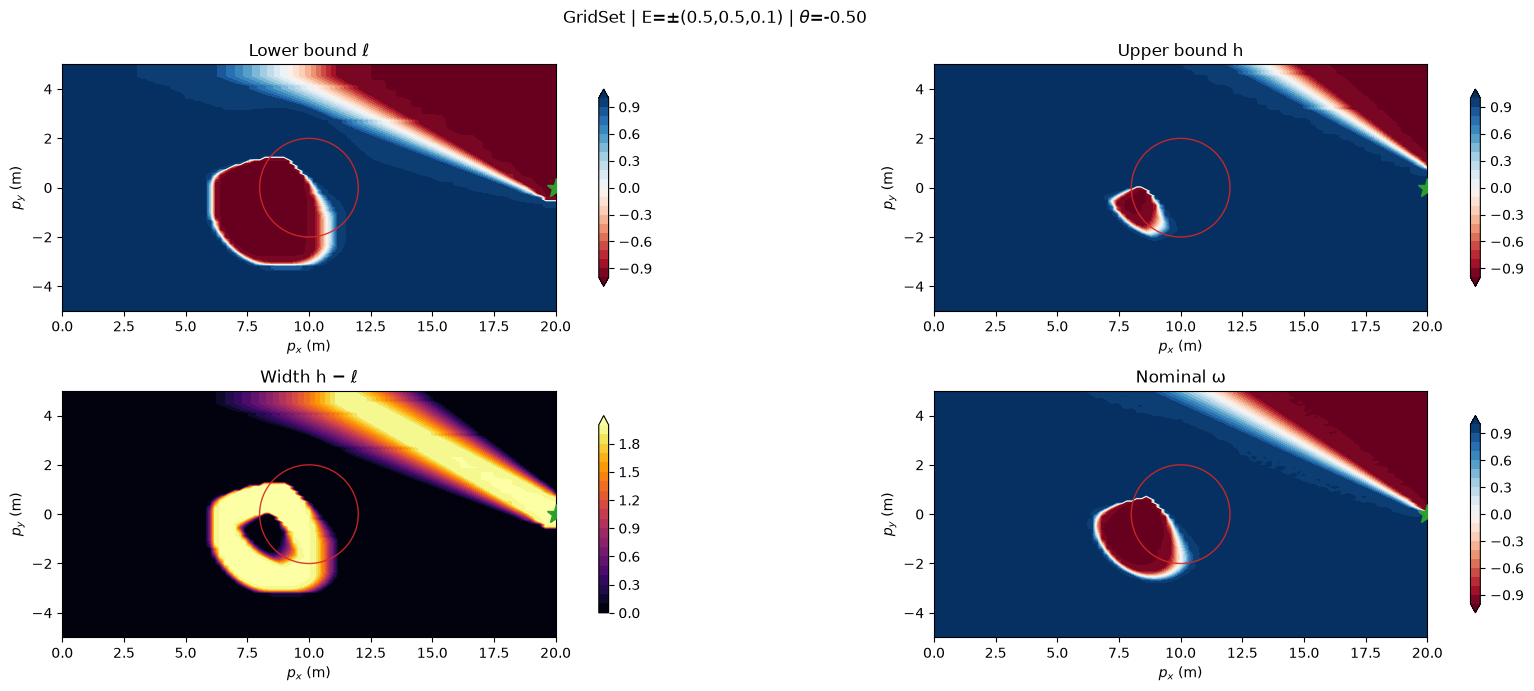

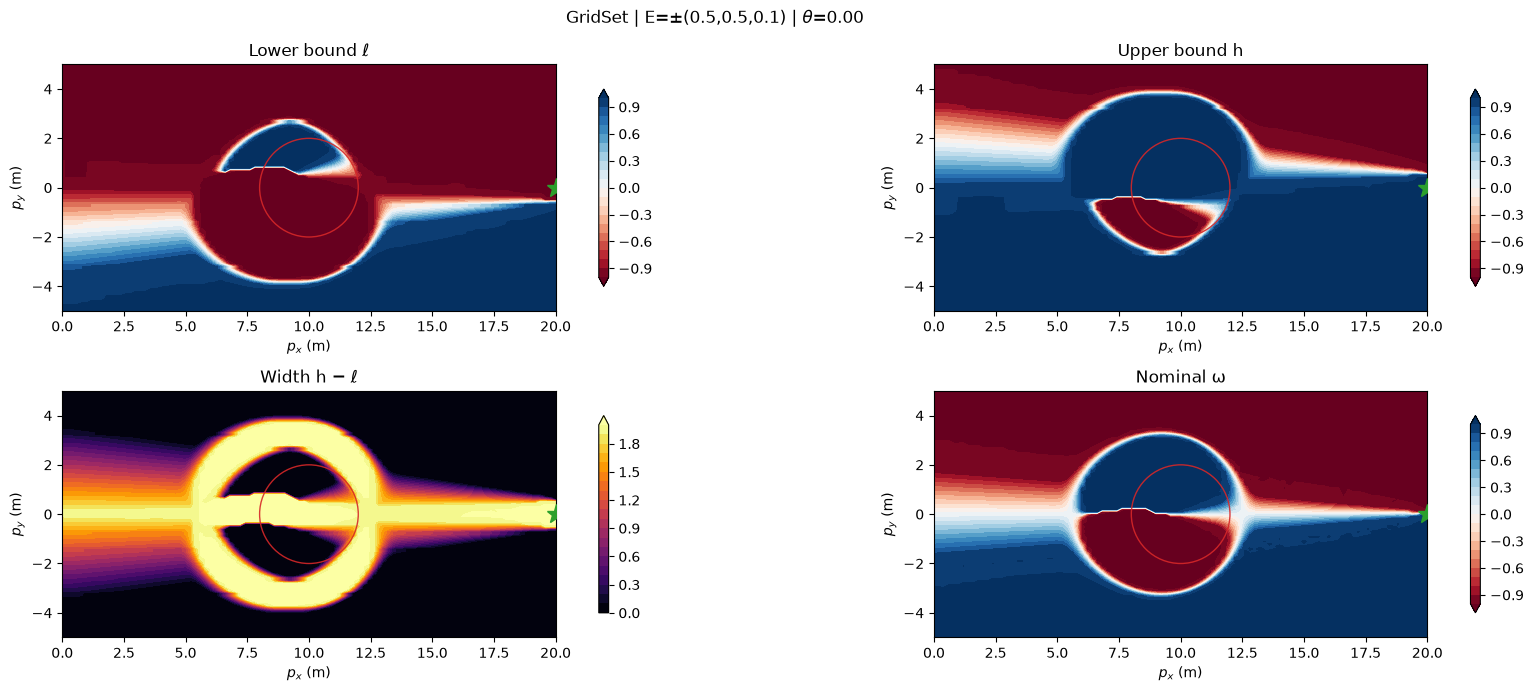

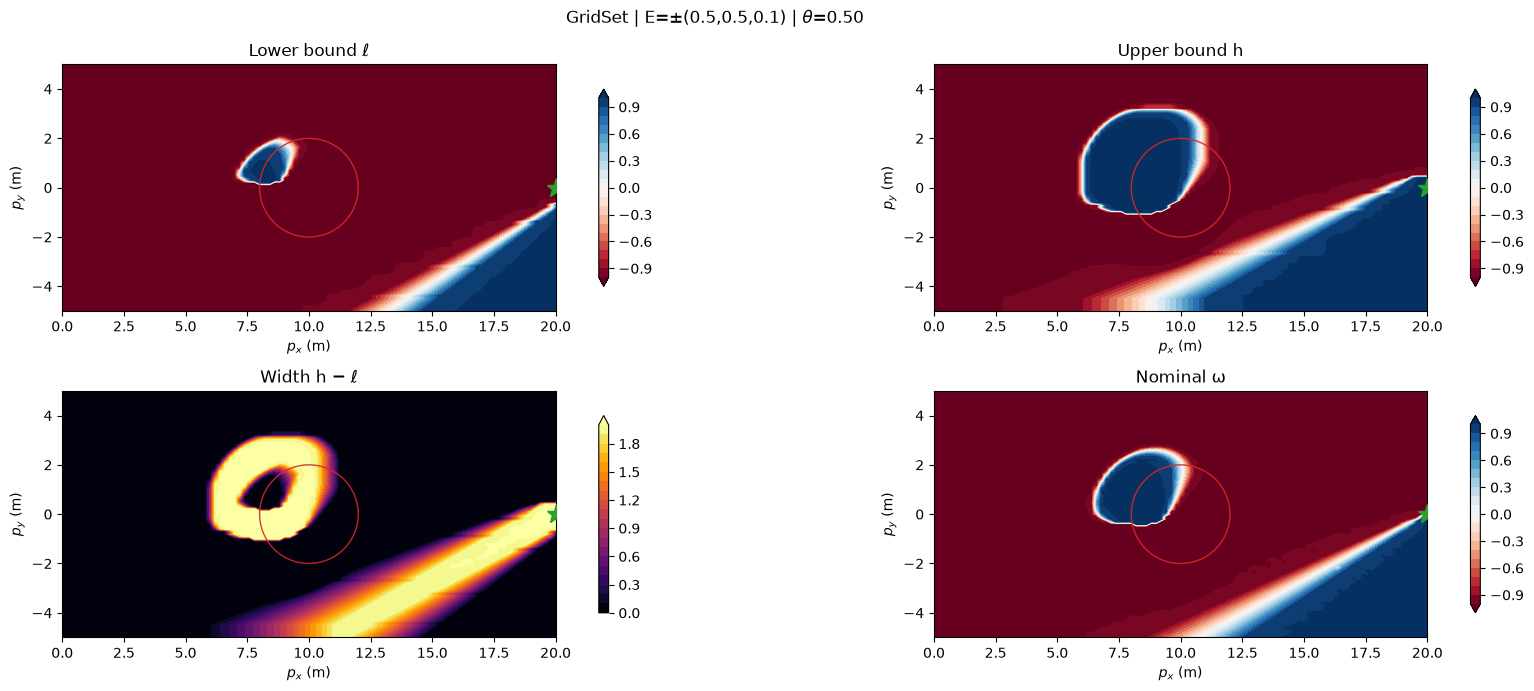

In [5]:
rebuilt_gs = rebuilt_gi or stale(grid_set.path(cfg))
gs = grid_set.build(cfg, gi) if rebuilt_gs else grid_set.load(cfg)
width = gs.upper - gs.lower
print(f"width: mean {width.mean():.3f}, max {width.max():.3f}, fraction > 0: {(width > 0).mean():.3f}")
for i, theta in enumerate(THETAS):
    fig = plot_grid_set(sys, gs, gi, theta)
    save_fig(fig, cfg, f"4_grid_set_{i}")
    plt.show()

## Simulation (GridInput controller): zero and random perception error

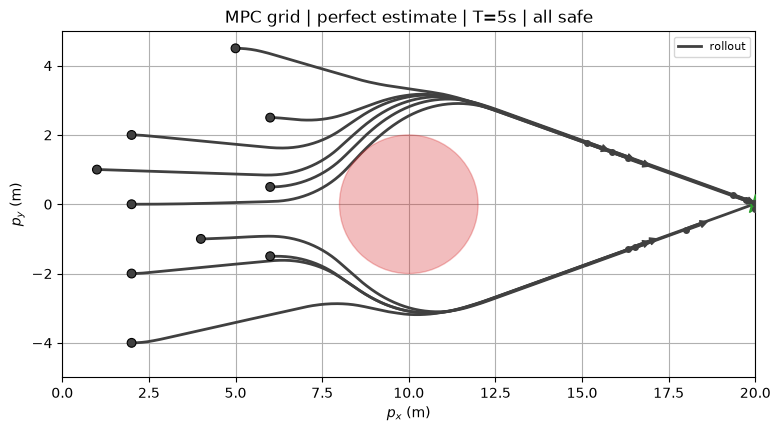

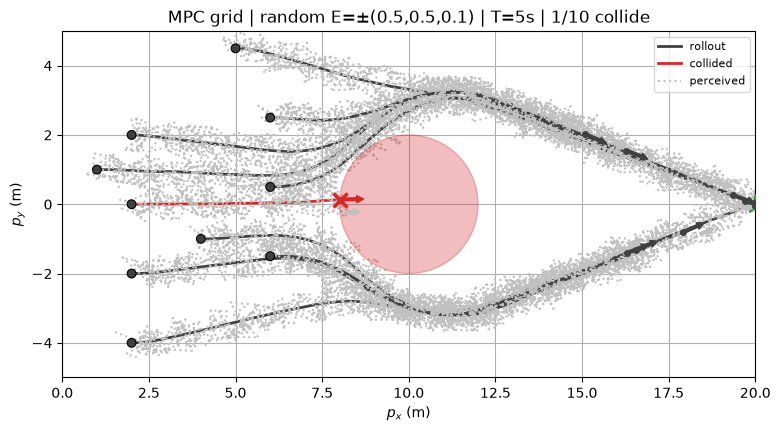

In [ ]:
for name, player in [("zero", uncertainty.zero()), ("random", uncertainty.uniform_random(sys, seed=0))]:
    ro = simulate(sys, gi, player, x0)
    fig = plot_rollout(sys, ro, rollout_title("MPC grid", name, sys, ro), show_estimate=name != "zero")
    save_fig(fig, cfg, f"6_sim_{name}")
    plt.show()

## 5. BRT
Nominal: ω = GridInput(x). Robust: ω = worst of [lower(x), upper(x)]. V < 0 inside the BRT; dashed = nominal, solid = robust zero level.

nominal: unsafe fraction at t=0 13.86%
robust: unsafe fraction at t=0 22.89%


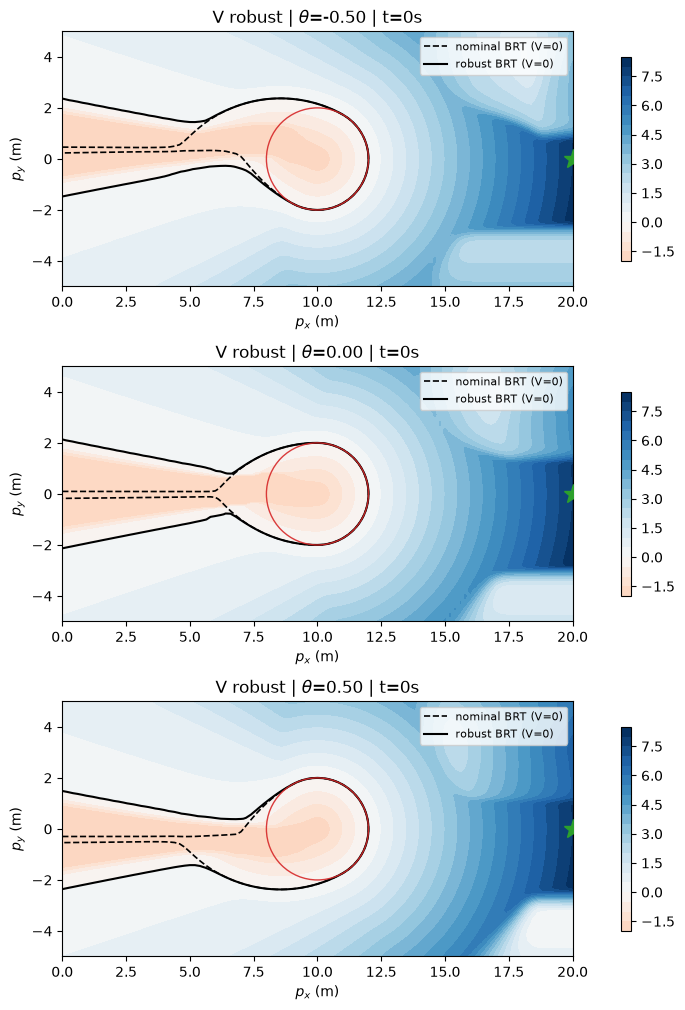

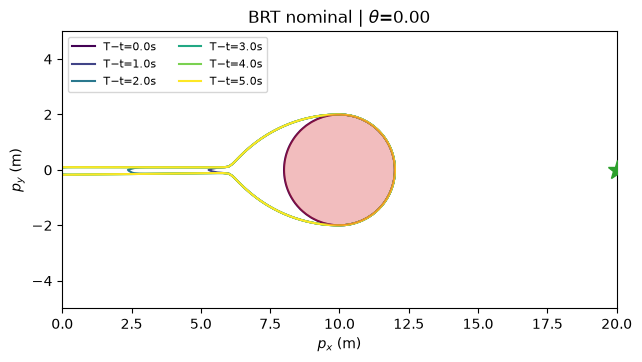

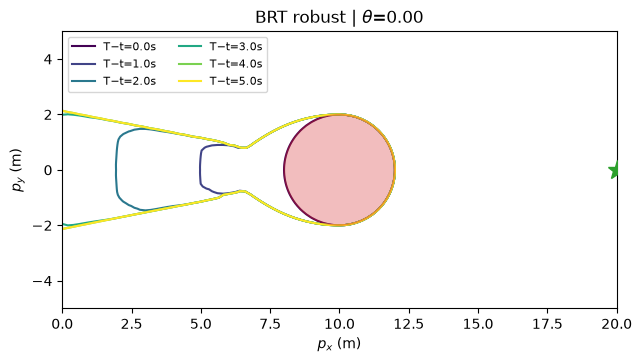

In [7]:
def value(kind, control, upstream_rebuilt):
    if upstream_rebuilt or stale(grid_value.path(cfg, kind)):
        return grid_value.build(cfg, kind, control)
    return grid_value.load(cfg, kind)

gv_nom = value("nominal", gi, rebuilt_gi)
gv_rob = value("robust", gs, rebuilt_gs)
for name, gv in [("nominal", gv_nom), ("robust", gv_rob)]:
    print(f"{name}: unsafe fraction at t=0 {(gv.values[0] < 0).mean():.2%}")
fig = plot_brt(sys, gv_nom, gv_rob, THETAS)
save_fig(fig, cfg, "5_brt")
plt.show()
for name, gv in [("nominal", gv_nom), ("robust", gv_rob)]:
    fig = plot_brt_tube(sys, gv, f"BRT {name}")
    save_fig(fig, cfg, f"5_brt_tube_{name}")
    plt.show()

## 6. Worst-case simulation
The player picks x̂ = the GridSet node attaining the bound that minimizes ∂V/∂θ ω (robust BRT gradient).

V robust(0, x0): [-1.997  0.485  0.071 -2.     0.093 -0.21   0.723  0.191 -2.     0.453]
V nominal(0, x0): [ 0.511  1.138  0.809 -0.109  0.819  0.552  1.307  0.814  0.289  1.048]


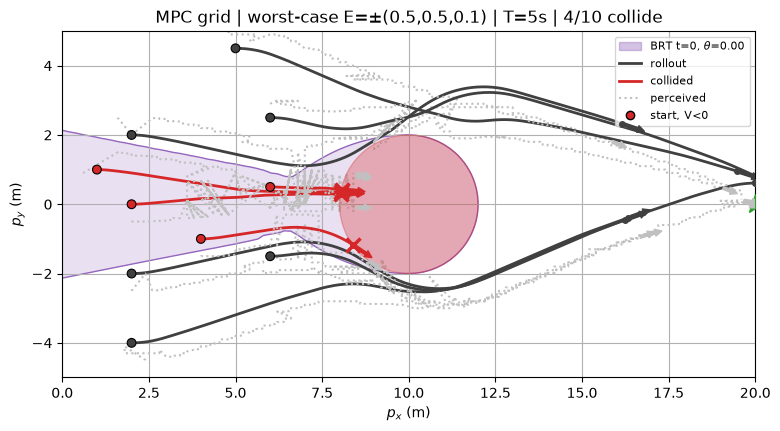

In [8]:
print("V robust(0, x0):", np.round(gv_rob.value(x0, 0.0), 3))
print("V nominal(0, x0):", np.round(gv_nom.value(x0, 0.0), 3))
ro_wc = simulate(sys, gi, uncertainty.worst_case(gv_rob, gs), x0)
fig = plot_rollout(sys, ro_wc, rollout_title("MPC grid", "worst-case", sys, ro_wc), brt=gv_rob)
save_fig(fig, cfg, "6_sim_worst_case")
plt.show()

## 7. BRT vs horizon and perception error
Robust BRT at θ = 0 with the error bound scaled to s·E (same GridInput controller); s = 0 is the nominal BRT.

In [ ]:
SCALES = (0.0, 0.5, 1.0, 1.5, 2.0)
SWEEP_THETA = 0.0
sweep_cfg = brt_sweep.sweep_config(cfg, SCALES, SWEEP_THETA)
if REBUILD or rebuilt_gi or not cache.is_current(brt_sweep.path(cfg), sweep_cfg):
    sw = brt_sweep.build(cfg, gi, SCALES, SWEEP_THETA)
else:
    sw = brt_sweep.load(cfg)
for s, v in zip(sw.scales, sw.values[:, 0]):
    print(f"s = {s:g}: unsafe fraction at t=0, θ={sw.theta:.2f}: {(v < 0).mean():.2%}")

In [ ]:
fig = plot_brt_sweep(sys, sw, horizons=(0.0, 1.0, 2.0, 3.0, 4.0, 5.0))
save_fig(fig, cfg, "7_brt_sweep")
plt.show()